In [1]:
import math
import sys
import time
from pathlib import Path
import shutil


import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets
from torchvision.transforms import v2
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torch.utils.tensorboard import SummaryWriter


import matplotlib.pyplot as plt


In [2]:
! pip install torch torchvision scikit-learn tensorboard matplotlib


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


## 1. Tenseurs, autograd, CPU/GPU

Un tenseur est un tableau à n dimensions, plus trois informations qui
détermineront 90 % des messages d'erreur que vous verrez cette semaine :
sa **forme** (`shape`), son **type** (`dtype`) et son **emplacement**
(`device`).

In [3]:
import torch
scalaire = torch.tensor(3.0)
vecteur = torch.tensor([1.0, 2.0, 3.0])
matrice = torch.randn(2, 3)


In [4]:
for nom, t in [("scalaire", scalaire), ("vecteur", vecteur), ("matrice", matrice)]:
    print(f"{nom:9s} shape={tuple(t.shape)!s:8s} dtype={t.dtype} device={t.device}")

scalaire  shape=()       dtype=torch.float32 device=cpu
vecteur   shape=(3,)     dtype=torch.float32 device=cpu
matrice   shape=(2, 3)   dtype=torch.float32 device=cpu


### Vectoriser plutôt que boucler

La raison d'être des tenseurs : une opération sur un gros tableau part dans du
code compilé et parallélisé, là où une boucle Python reste... une boucle
Python. C'est le même calcul, plusieurs ordres de grandeur d'écart.

In [5]:
import time

a = torch.randn(200_000)
b = torch.randn(200_000)

debut = time.perf_counter()
resultat_boucle = [x * y for x, y in zip(a.tolist(), b.tolist())]
duree_boucle = time.perf_counter() - debut

debut = time.perf_counter()
resultat_tenseur = a * b
duree_tenseur = time.perf_counter() - debut

print(f"boucle Python : {duree_boucle * 1000:7.1f} ms")
print(f"tenseur       : {duree_tenseur * 1000:7.1f} ms")
print(f"facteur       : x{duree_boucle / max(duree_tenseur, 1e-9):.0f}")

boucle Python :    16.3 ms
tenseur       :     1.4 ms
facteur       : x12


### Autograd : exactement micrograd, mais sur des tableaux

`requires_grad=True` demande à PyTorch de construire le graphe de calcul au
fil des opérations — précisément ce que faisait `_prev` / `_backward` dans
micrograd. `backward()` le remonte et remplit `.grad`.

In [6]:
x = torch.tensor([2.0], requires_grad=True)
w = torch.tensor([-3.0], requires_grad=True)
b = torch.tensor([6.881373587019543], requires_grad=True)

sortie = torch.tanh(x * w + b)
sortie.backward()

print("sortie  =", sortie.item())
print("x.grad  =", x.grad.item())  # identique au resultat obtenu a la main en micrograd
print("w.grad  =", w.grad.item())

sortie  = 0.7071067094802856
x.grad  = -1.5000003576278687
w.grad  = 1.000000238418579


Deux réflexes qui reviendront tout le temps :

- `.grad` **s'accumule** (comme le `+=` de micrograd) : d'où le
  `optimiseur.zero_grad()` au début de chaque itération ;
- `torch.no_grad()` désactive la construction du graphe. Indispensable en
  évaluation : sans lui, on paie de la mémoire et du temps pour des gradients
  dont on ne fera rien.

In [7]:
sortie2 = torch.tanh(x * w + b)
sortie2.backward()
print("x.grad apres un 2e backward sans remise a zero :", x.grad.item(), "(le double : ca s'accumule)")

x.grad = None  # remise a zero manuelle ; l'optimiseur le fera pour nous ensuite

with torch.no_grad():
    sortie_sans_graphe = torch.tanh(x * w + b)
print("requires_grad sous no_grad() :", sortie_sans_graphe.requires_grad)

x.grad apres un 2e backward sans remise a zero : -3.0000007152557373 (le double : ca s'accumule)
requires_grad sous no_grad() : False


### Le GPU ne paie que sur de gros tenseurs

Transférer des données coûte du temps. Sur les modèles minuscules de ce
module, le CPU gagne largement — on y restera donc pour toutes les sections
suivantes. Le GPU devient indispensable quand les tenseurs deviennent gros,
ce que le petit banc d'essai ci-dessous rend visible.


In [8]:
def chronometre_matmul(taille, device_cible, repetitions=3):
    """Mesure le temps d'un produit matriciel carré sur un device donné.

    Args:
        taille: Côté des matrices carrées multipliées.
        device_cible: Device sur lequel effectuer le calcul.
        repetitions: Nombre de produits enchaînés, pour lisser la mesure.

    Returns:
        La durée moyenne d'un produit, en millisecondes.
    """
    m1 = torch.randn(taille, taille, device=device_cible)
    m2 = torch.randn(taille, taille, device=device_cible)

    def synchronise():
        """Attend la fin des calculs asynchrones du GPU avant de lire l'horloge."""
        if device_cible.type == "cuda":
            torch.cuda.synchronize()
        elif device_cible.type == "mps":
            torch.mps.synchronize()

    m1 @ m2  # tour de chauffe : la 1re allocation sur GPU est toujours lente
    synchronise()

    debut = time.perf_counter()
    for _ in range(repetitions):
        m1 @ m2
    synchronise()
    return (time.perf_counter() - debut) / repetitions * 1000

device = torch.device("mps")
for taille in (64, 2048):
    duree_cpu = chronometre_matmul(taille, torch.device("cpu"))
    ligne = f"matmul {taille:5d}x{taille:<5d}  cpu {duree_cpu:8.2f} ms"
    if device.type != "cpu":
        duree_gpu = chronometre_matmul(taille, device)
        ligne += f"  |  {device.type} {duree_gpu:8.2f} ms  (x{duree_cpu / max(duree_gpu, 1e-9):.1f})"
    print(ligne)

matmul    64x64     cpu     0.03 ms  |  mps     0.15 ms  (x0.2)
matmul  2048x2048   cpu     9.63 ms  |  mps     7.54 ms  (x1.3)


## 2. Datasets & DataLoaders

PyTorch sépare deux responsabilités. Un **`Dataset`** sait fournir *un*
exemple à la fois (`dataset[i]` renvoie un couple `(features, label)`). Un
**`DataLoader`** empile ces exemples en batchs, les mélange, et gère le
parallélisme de chargement.

In [9]:
DATA_DIR = Path.cwd() / "data"

In [10]:


transform = v2.Compose(
    [
        v2.ToImage(),                                  # PIL → tenseur uint8 [1, 28, 28]
        v2.ToDtype(torch.float32, scale=True),         # uint8 0-255 → float32 0.0-1.0
    ]
)

training_data = datasets.MNIST(root=DATA_DIR, train=True, download=True, transform=transform)
test_data = datasets.MNIST(root=DATA_DIR, train=False, download=True, transform=transform)

print(f"training_data : {len(training_data)} exemples")
print(f"test_data     : {len(test_data)} exemples")

image, label = training_data[0]
print(f"\nun item : shape={tuple(image.shape)}  dtype={image.dtype}")
print(f"          min={image.min():.2f}  max={image.max():.2f}  label={label}")

training_data : 60000 exemples
test_data     : 10000 exemples

un item : shape=(1, 28, 28)  dtype=torch.float32
          min=0.00  max=1.00  label=5


## Visualisation des images

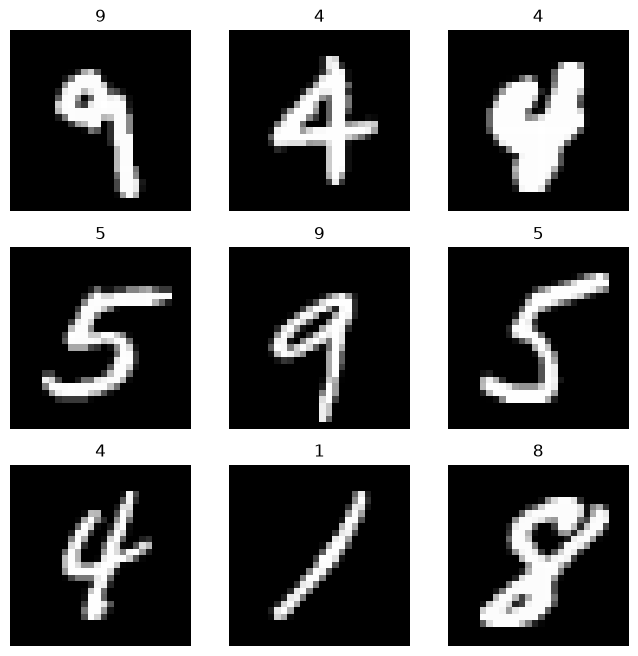

In [11]:
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(label)
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

Le `DataLoader` transforme ce jeu en un itérable de batchs. Noter la forme
renvoyée : `[batch, channel, height, width]`, la convention PyTorch pour les
images. Le canal unique est celui du niveau de gris.

In [12]:
train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=False)

train_features, train_labels = next(iter(train_dataloader))
print(f"features batch : {tuple(train_features.shape)}  {train_features.dtype}")
print(f"labels batch   : {tuple(train_labels.shape)}  {train_labels.dtype}")

features batch : (64, 1, 28, 28)  torch.float32
labels batch   : (64,)  torch.int64


### Écrire son propre `Dataset`

Le tutoriel officiel montre comment implémenter les trois méthodes
obligatoires — `__init__`, `__len__`, `__getitem__` — sur un dossier
d'images. On fait la même chose ici sur des tenseurs déjà en mémoire, ce qui
servira à toute la partie II.

Pourquoi ne pas garder le `Dataset` de torchvision partout ? Parce qu'il
décode une image PIL et applique les transforms **à chaque accès**. Mesuré
ici : 0,39 s par epoch contre 0,04 s avec les tenseurs pré-calculés, soit dix
fois plus lent. La partie II enchaîne une vingtaine d'entraînements ; à ce
prix-là, on préfère payer la préparation une seule fois.

In [13]:
class DigitsDataset(Dataset):
    """Jeu de chiffres déjà chargé en mémoire, prêt pour un `DataLoader`.

    Implémente le protocole `Dataset` de PyTorch. C'est l'équivalent de
    `TensorDataset`, écrit explicitement pour montrer les trois méthodes que
    n'importe quel jeu de données personnalisé doit fournir.

    Args:
        features: Tenseur `(n, ...)` des entrées.
        labels: Tenseur `(n,)` des classes attendues, en `int64`.
    """

    def __init__(self, features, labels):
        if len(features) != len(labels):
            raise ValueError(f"{len(features)} features pour {len(labels)} labels")
        self.features = features
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.features[index], self.labels[index]

## 3. Transforms

Les données ne sont presque jamais dans la forme attendue par le modèle. Les
*transforms* sont la couche de préparation, appliquée à la volée par le
`Dataset`.

Le `v2.Compose` utilisé plus haut fait déjà deux choses : convertir en tenseur
et ramener les pixels dans `[0, 1]`. Il manque la troisième, la plus
importante pour l'entraînement : **centrer-réduire**.

In [14]:
raw_pixels = training_data.data.float() / 255.0
print(f"après ToDtype(scale=True) : moyenne {raw_pixels.mean():.4f}  écart-type {raw_pixels.std():.4f}")

# Statistiques calculées sur le TRAIN uniquement — voir le chapitre 8 pour la
# raison, et le cas n°3 du chapitre 12 pour ce qui arrive quand on l'oublie.
MNIST_MEAN = raw_pixels[:12_000].mean().item()
MNIST_STD = raw_pixels[:12_000].std().item()

normalizing_transform = v2.Compose(
    [
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=(MNIST_MEAN,), std=(MNIST_STD,)),
    ]
)

normalized_data = datasets.MNIST(root=DATA_DIR, train=True, download=False, transform=normalizing_transform)
image, _ = normalized_data[0]
print(f"après Normalize           : moyenne {image.mean():+.4f}  min {image.min():.3f}  max {image.max():.3f}")
print(f"\nstatistiques retenues : mean={MNIST_MEAN:.4f}  std={MNIST_STD:.4f}")

après ToDtype(scale=True) : moyenne 0.1307  écart-type 0.3081
après Normalize           : moyenne +0.0190  min -0.426  max 2.804

statistiques retenues : mean=0.1318  std=0.3096


## 4. Build the Model


Tout ce qu'on avait écrit à la main en micrograd (neurone, couche, MLP,
`parameters()`) tient désormais dans une sous-classe de `nn.Module`. Deux
méthodes suffisent : `__init__` déclare les couches, `forward` décrit le
chemin du calcul.

`nn.Flatten` aplatit `[batch, 1, 28, 28]` en `[batch, 784]`. `nn.Linear`
contient déjà poids et biais, initialisés intelligemment, et gère le batch.

Une seule différence de fond avec micrograd : la sortie a **dix** valeurs (une
par chiffre) au lieu d'une. Ce sont des *logits*, des scores non normalisés ;
c'est `nn.CrossEntropyLoss` qui les transforme en probabilités, et la classe
prédite est celle qui a le plus grand score (`argmax`).

In [15]:
class NeuralNetwork(nn.Module):
    """Le MLP de référence, activations ReLU."""

    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

In [16]:
model = NeuralNetwork()
print(model)
print(f"\nnombre de paramètres : {sum(p.numel() for p in model.parameters()):,}")

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)

nombre de paramètres : 669,706


In [17]:
logits = model(train_features[:3])
predicted_probab = nn.Softmax(dim=1)(logits)
print(f"\nlogits          : {tuple(logits.shape)}")
print(f"probabilités    : somme = {predicted_probab[0].sum():.4f} (softmax normalise bien)")
print(f"classes prédites (modèle non entraîné) : {logits.argmax(1).tolist()}")
print(f"vraies classes                          : {train_labels[:3].tolist()}")


logits          : (3, 10)
probabilités    : somme = 1.0000 (softmax normalise bien)
classes prédites (modèle non entraîné) : [5, 5, 5]
vraies classes                          : [2, 1, 4]


## 5. Optimization Loop

**forward** (prédire) → **loss** (mesurer l'erreur) → **backward** (calculer
les gradients) → **step** (corriger les poids). Ces quatre lignes sont tout
l'entraînement ; le reste du module ne fait que changer ce qu'on y branche.

Vocabulaire, souvent confondu :

- **batch** : un paquet d'exemples traités ensemble en un forward/backward ;
- **step** (ou itération) : une mise à jour des poids, donc un batch ;
- **epoch** : un passage complet sur le jeu d'entraînement, donc
  `len(dataset) / batch_size` steps.

Pourquoi des batchs plutôt que tout le dataset d'un coup ? Parce qu'on ne peut
pas toujours tout charger en mémoire — 60 000 images ici, mais des millions en vrai — et surtout parce que le bruit d'échantillonnage aide à sortir des
mauvais minima.

In [ ]:
model = model.to(device)

learning_rate = 1e-3
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr= learning_rate)

In [20]:
def train_loop(dataloader, model, loss_fn, optimizer, verbose=True, writer=None, epoch=None):
    """Un passage complet sur le jeu d'entraînement."""
    size = len(dataloader.dataset)
    model.train()
    running_loss, seen = 0.0, 0

    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)
        pred = model(X)                 # 1. forward
        loss = loss_fn(pred, y)         # 2. loss

        loss.backward()                 # 3. backward
        optimizer.step()                # 4. step
        optimizer.zero_grad()           # 5. remise à zéro des gradients

        running_loss += loss.item() * len(X)
        seen += len(X)
        if verbose and batch % 100 == 0:
            print(f"    loss: {loss.item():>7f}  [{seen:>5d}/{size:>5d}]")

    train_loss = running_loss / seen
    if writer is not None:
        writer.add_scalar("loss/train", train_loss, epoch)
        writer.add_scalar("lr", optimizer.param_groups[0]["lr"], epoch)
    return train_loss

In [21]:
def test_loop(dataloader, model, loss_fn, verbose=True, writer=None, epoch=None):
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0.0, 0

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size
    if verbose:
        print(f"  Test Error: Accuracy {100 * correct:>0.1f}%, Avg loss {test_loss:>8f}")
    if writer is not None:
        writer.add_scalar("loss/val", test_loss, epoch)
        writer.add_scalar("accuracy/val", correct, epoch)
    return test_loss, correct

In [22]:
epochs = 2

for t in range(epochs):
    print(f"Epoch {t + 1}\n-------------------------------")
    train_loop(train_dataloader, model, loss_fn, optimizer)
    test_loop(test_dataloader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
    loss: 2.302984  [   64/60000]
    loss: 0.342230  [ 6464/60000]
    loss: 0.284336  [12864/60000]
    loss: 0.120084  [19264/60000]
    loss: 0.376981  [25664/60000]
    loss: 0.069303  [32064/60000]
    loss: 0.275588  [38464/60000]
    loss: 0.182469  [44864/60000]
    loss: 0.123979  [51264/60000]
    loss: 0.109030  [57664/60000]
  Test Error: Accuracy 94.2%, Avg loss 0.226196
Epoch 2
-------------------------------
    loss: 0.454045  [   64/60000]
    loss: 0.228740  [ 6464/60000]
    loss: 0.181397  [12864/60000]
    loss: 0.189767  [19264/60000]
    loss: 0.143701  [25664/60000]
    loss: 0.278355  [32064/60000]
    loss: 0.072006  [38464/60000]
    loss: 0.138159  [44864/60000]
    loss: 0.410001  [51264/60000]
    loss: 0.188455  [57664/60000]
  Test Error: Accuracy 95.8%, Avg loss 0.147288
Done!


## 7. Save & Load the Model


Un modèle entraîné ne sert à rien s'il disparaît avec le processus. PyTorch
sauvegarde le **`state_dict`** : un dictionnaire des poids, sans le code du
modèle. Il faut donc recréer la classe avant de recharger les poids.

`weights_only=True` est la bonne pratique de sécurité : elle empêche
`torch.load` d'exécuter du code arbitraire caché dans le fichier — un fichier
de poids téléchargé est du code potentiellement hostile tant qu'on ne s'en
protège pas.

In [34]:
weights_path = Path.cwd() / "mnist_weights.pth"
torch.save(model.state_dict(), weights_path)
print(f"poids sauvegardés dans {weights_path.name} ({weights_path.stat().st_size // 1024} Ko)")

poids sauvegardés dans mnist_weights.pth (2619 Ko)


# Partie II — Régler et déboguer

## 8. Train / validation / test

Le tutoriel n'utilise que deux jeux, train et test. En pratique il en faut
**trois**, avec trois rôles distincts :

- **train** : le modèle apprend dessus ;
- **validation** : on y règle les hyperparamètres et on décide quand arrêter ;
- **test** : on n'y touche **qu'une fois**, à la toute fin.

On matérialise ici les trois jeux en tenseurs, une fois pour toutes, pour les
raisons de vitesse expliquées au chapitre 2.

In [25]:
train_data, validation_data = torch.utils.data.random_split(training_data, [0.8, 0.2])

In [26]:
print(f"train {len(train_data)}   val {len(validation_data)}   test {test_data.data.shape}")


train 48000   val 12000   test torch.Size([10000, 28, 28])


In [27]:
data = train_data.dataset.data[train_data.indices].float()/255
mean, std = data.mean(), data.std()
mean, std

(tensor(0.1306), tensor(0.3081))

In [28]:
normalizing_transform = v2.Compose(
    [
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=(mean,), std=(std,)),
    ]
)

train_data, val_data, test_data = normalizing_transform(train_data, validation_data, test_data)
train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
validation_dataloader = DataLoader(val_data, batch_size=64, shuffle=False)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=False)

In [29]:
RUNS_DIR = Path.cwd() / "runs"

def make_writer(experiment, run=None):
    """Ouvre un `SummaryWriter` sur `runs/<experiment>/<run>`.

    Le dossier est vidé au préalable : réexécuter une cellule remplace ses
    courbes au lieu d'en empiler une seconde copie par-dessus la première.

    Args:
        experiment: Nom de l'expérience, préfixé par son numéro de chapitre.
        run: Nom du run à l'intérieur de l'expérience, ou `None` s'il n'y en a
            qu'un.

    Returns:
        Le `SummaryWriter`, à utiliser dans un bloc `with` pour qu'il soit
        fermé — et ses données écrites sur disque — à la sortie.
    """
    log_dir = RUNS_DIR / experiment / run if run else RUNS_DIR / experiment
    shutil.rmtree(log_dir, ignore_errors=True)
    return SummaryWriter(log_dir=str(log_dir))


In [30]:
writer = make_writer("Reference")
model = NeuralNetwork().to(device)
loss_fn = nn.CrossEntropyLoss()
learning_rate = 1e-3
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

epochs = 5
for epoch in range(1, epochs + 1):
    train_loop(train_dataloader, model, loss_fn, optimizer, verbose=False, writer=writer, epoch=epoch)
    test_loop(validation_dataloader, model, loss_fn, verbose=False, writer=writer, epoch=epoch)

## Matrice de Confusion

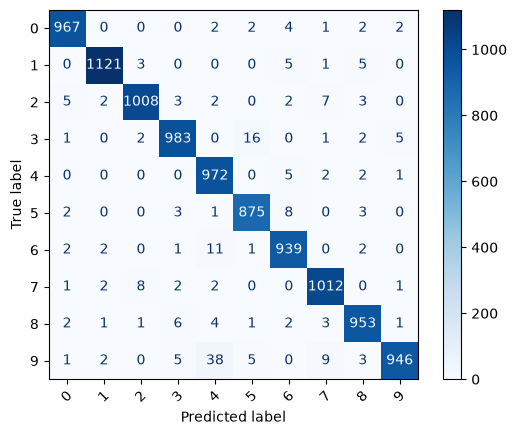

In [31]:
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for x, y in test_dataloader:
        x = x.to(device)
        logits = model(x)
        preds = logits.argmax(dim=1)
        all_preds.append(preds.cpu())
        all_labels.append(y)

y_pred = torch.cat(all_preds).numpy()
y_true = torch.cat(all_labels).numpy()

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.show()

In [32]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm).plot(ax=ax, cmap="Blues")
writer.add_figure("Confusion matrix", fig)